# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task A3: Dry Bean Variety Recognition (Multi-Class Classification & Dimensionality Reduction)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("A3 Multi-class Dry Bean recognition loaded with inline plotting!")


A3 Multi-class Dry Bean recognition loaded with inline plotting!


In [2]:
# 2. Data Loading & Inspection
df = pd.read_csv("data/dry_bean_dataset.csv")
print(f"Dataset shape: {df.shape[0]} grains x {df.shape[1]} attributes")
print("\nClass Distribution:")
print(df['Class'].value_counts())
print("\nSummary Statistics of Core Morphological Attributes:")
display(df[['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Roundness']].describe().T[['mean', 'std', 'min', 'max']].round(2))


Dataset shape: 3500 grains x 17 attributes

Class Distribution:
Class
Dermason    910
Sira        665
Seker       525
Horoz       490
Cali        420
Barbunya    350
Bombay      140


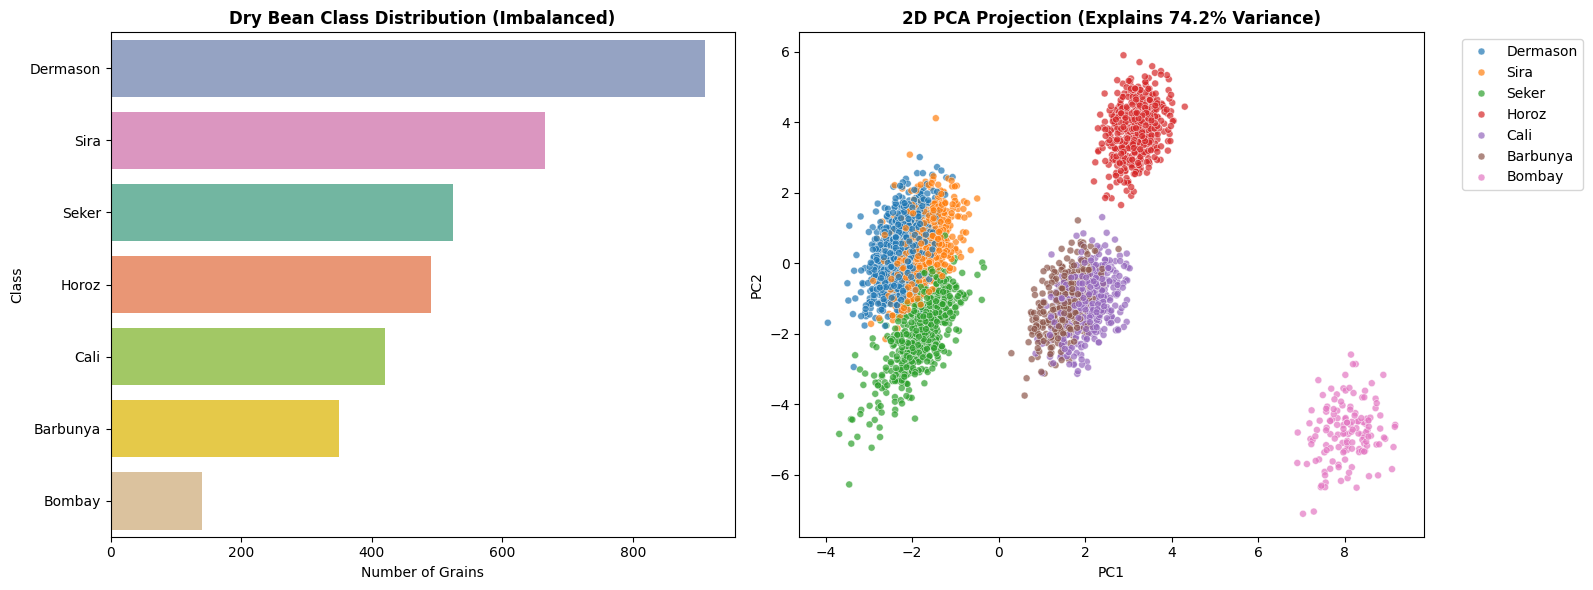

In [3]:
# 3. Exploratory Data Analysis (EDA) & 2D PCA Projection
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Class balance barplot
classes = ['Dermason', 'Sira', 'Seker', 'Horoz', 'Cali', 'Barbunya', 'Bombay']
sns.countplot(y='Class', hue='Class', data=df, order=classes, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title("Dry Bean Class Distribution (Imbalanced)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Grains")

# 2D PCA projection colored by variety
feature_names = [c for c in df.columns if c != 'Class']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_names])
pca_2d = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca_2d.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Class'] = df['Class']

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Class', hue_order=classes, palette='tab10', ax=axes[1], alpha=0.7, s=25)
axes[1].set_title(f"2D PCA Projection (Explains {pca_2d.explained_variance_ratio_.sum():.1%} Variance)", fontsize=12, fontweight='bold')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


In [4]:
# 4. Stratified 70/15/15 Disjoint Splitting (Module 02 Protocol)
X_data = df[feature_names]
y_data = df['Class']

X_train, X_temp, y_train, y_temp = train_test_split(
    X_data, y_data, test_size=0.30, random_state=RANDOM_SEED, stratify=y_data
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(f"Training set:   {X_train.shape[0]} samples ({X_train.shape[0]/len(df):.1%})")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(df):.1%})")
print(f"Testing set:    {X_test.shape[0]} samples ({X_test.shape[0]/len(df):.1%})")


Training set:   2450 samples (70.0%)
Validation set: 525 samples (15.0%)
Testing set:    525 samples (15.0%)


In [5]:
# 5. Multi-Class Model Benchmarking (StandardScaler Pipelines)
models_a3 = {
    "Multinomial Logistic Regression": Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))]),
    "Logistic Regression (Balanced)": Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))]),
    "SVM (RBF Kernel)": Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', C=10.0, random_state=RANDOM_SEED))]),
    "Random Forest": Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_SEED))])
}

res_a3 = {}
print(f"{'Model Architecture':<35} | Accuracy | Macro-F1 | Weighted-F1")
print("-" * 75)
for name, pipe in models_a3.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average='macro')
    weighted_f1 = f1_score(y_test, preds, average='weighted')
    res_a3[name] = {"acc": acc, "macro_f1": macro_f1, "weighted_f1": weighted_f1, "preds": preds}
    print(f"{name:<35} | {acc:.4f}   | {macro_f1:.4f}   | {weighted_f1:.4f}")


Model Architecture                  | Accuracy | Macro-F1 | Weighted-F1
---------------------------------------------------------------------------
Multinomial Logistic Regression     | 0.8533   | 0.8644   | 0.8522
Logistic Regression (Balanced)      | 0.8476   | 0.8652   | 0.8479
SVM (RBF Kernel)                    | 0.8552   | 0.8616   | 0.8541
Random Forest                       | 0.8552   | 0.8641   | 0.8540


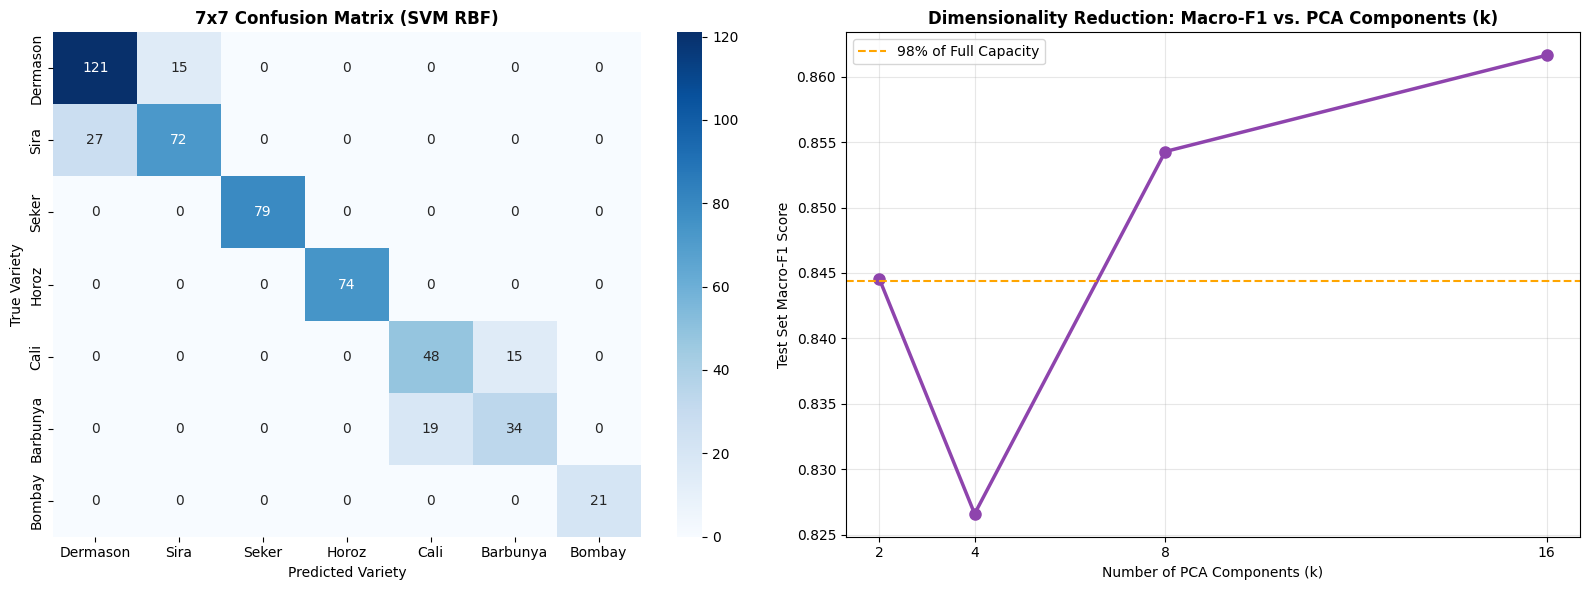

PCA Retention Summary: k=2 retains 98.0% Macro-F1; k=8 retains 99.2% Macro-F1.


In [6]:
# 6. Error Analysis: 7x7 Confusion Matrix & PCA Dimensionality Study
best_preds = res_a3["SVM (RBF Kernel)"]["preds"]
cm = confusion_matrix(y_test, best_preds, labels=classes)

k_values = [2, 4, 8, 16]
k_f1s = []
for k in k_values:
    p_k = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=k, random_state=RANDOM_SEED)),
        ('clf', SVC(kernel='rbf', C=10.0, random_state=RANDOM_SEED))
    ])
    p_k.fit(X_train, y_train)
    pred_k = p_k.predict(X_test)
    k_f1s.append(float(f1_score(y_test, pred_k, average='macro')))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=classes, yticklabels=classes)
axes[0].set_title("7x7 Confusion Matrix (SVM RBF)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Variety")
axes[0].set_ylabel("True Variety")

# Macro-F1 vs PCA components
axes[1].plot(k_values, k_f1s, marker='o', color='#8e44ad', lw=2.5, markersize=8)
axes[1].axhline(k_f1s[-1] * 0.98, color='orange', linestyle='--', label='98% of Full Capacity')
axes[1].set_title("Dimensionality Reduction: Macro-F1 vs. PCA Components (k)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of PCA Components (k)")
axes[1].set_ylabel("Test Set Macro-F1 Score")
axes[1].set_xticks(k_values)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"PCA Retention Summary: k=2 retains {k_f1s[0]/k_f1s[-1]:.1%} Macro-F1; k=8 retains {k_f1s[2]/k_f1s[-1]:.1%} Macro-F1.")
